<a href="https://colab.research.google.com/github/yeyevtushenko/Methods-and-Technologies-of-Computational-Intelligence/blob/main/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D0%B8_%D1%82%D0%B0_%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D1%96%D1%97_%D0%BE%D0%B1%D1%87%D0%B8%D1%81%D0%BB%D1%8E%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B3%D0%BE_%D1%96%D0%BD%D1%82%D0%B5%D0%BB%D0%B5%D0%BA%D1%82%D1%83_%D0%97%D0%9A_61%D0%9F%D0%9C_%D0%84%D0%B2%D1%82%D1%83%D1%88%D0%B5%D0%BD%D0%BA%D0%BE_%D0%BF%D1%80%D0%BE%D0%B4%D0%B2%D0%B8%D0%BD%D1%83%D1%82%D0%B8%D0%B9_%D0%9B%D0%B0%D0%B1%E2%84%963.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Імпорт бібліотек

In [1]:
%pip install -q scikit-fuzzy

import time
import operator
import functools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import skfuzzy as fuzz
from skfuzzy import control as ctrl

from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, classification_report, confusion_matrix

warnings.filterwarnings('ignore')

# Завдання 1. Fuzzy pipeline та базова система з чотирма входами

> Відтворити повний fuzzy pipeline та базову систему з чотирма входами.

Дані: Pima Indians Diabetes Database. Файл Kaggle потребує власного API token, тому той самий набір (стовпці `Pregnancies`, `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`, `DiabetesPedigreeFunction`, `Age`, `Outcome`) завантажується з відкритого дзеркала на GitHub.

In [ ]:
df = pd.read_csv("https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv")

print(df.shape)
print(df.head())
print(df.info())
print(df["Outcome"].value_counts())
print(df.describe().T)

features = ["Glucose", "BMI", "Age", "BloodPressure"]
print(df[features].isna().sum())
print((df[["Glucose", "BMI", "BloodPressure"]] == 0).sum())

(768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 n

Набір містить 768 записів і 9 стовпців без формально пропущених значень, класи нерівні: 500 без діабету (Outcome = 0) і 268 з діабетом (Outcome = 1). Проте мінімум `Glucose`, `BMI` і `BloodPressure` у `describe` дорівнює 0, а це фізіологічно неможливо: нулів 5 у `Glucose`, 11 у `BMI` і 35 у `BloodPressure`. Це приховані пропуски, тому далі їх замінено медіаною, як вимагає теорія. Чотири фактори системи (`Glucose`, `BMI`, `Age`, `BloodPressure`) формально пропусків не мають.

In [ ]:
for col in ["Glucose", "BMI", "BloodPressure"]:
    df[col] = df[col].replace(0, np.nan)
    df[col] = df[col].fillna(df[col].median())

print(df["Outcome"].value_counts(normalize=True))
print(df[features].describe().T)

Outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64
               count        mean        std   min    25%    50%     75%    max
Glucose        768.0  121.656250  30.438286  44.0  99.75  117.0  140.25  199.0
BMI            768.0   32.455208   6.875177  18.2  27.50   32.3   36.60   67.1
Age            768.0   33.240885  11.760232  21.0  24.00   29.0   41.00   81.0
BloodPressure  768.0   72.386719  12.096642  24.0  64.00   72.0   80.00  122.0


Нулі в `Glucose`, `BMI` і `BloodPressure` замінено на NaN, а потім медіанами ненульових значень (117, 32.3 і 72). Частки класів: 65.1% і 34.9%, тобто клас «діабет» менший, тому далі застосовується Balanced Accuracy. Після очищення мінімальні значення стали 44 для `Glucose`, 18.2 для `BMI` і 24 для `BloodPressure`, максимуми 199, 67.1 і 122. Один пацієнт має `Glucose` нижче 50, один `BMI` вище 60 і чотири мають `BloodPressure` нижче 40, тому при обчисленні ризику значення обрізаються до меж універсумів (50–250, 10–60, 40–140).

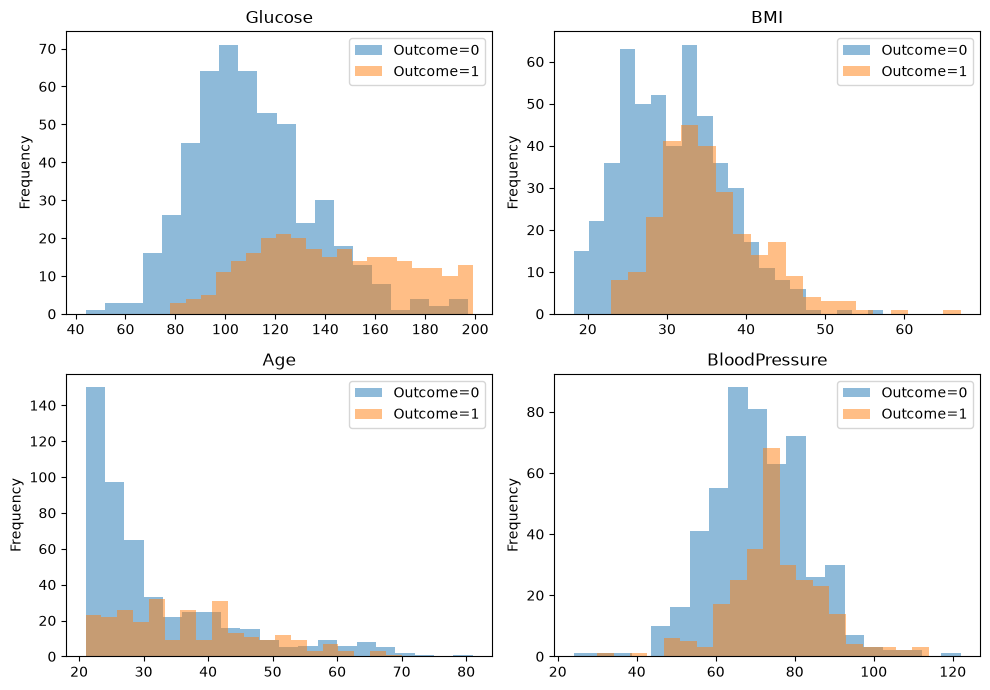

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax, col in zip(axes.ravel(), features):
    for cls in [0, 1]:
        df.loc[df["Outcome"] == cls, col].plot(
            kind="hist", bins=20, alpha=0.5, ax=ax,
            label=f"Outcome={cls}"
        )
    ax.set_title(col)
    ax.legend()

plt.tight_layout()
plt.show()

Розподіли двох класів помітно відрізняються за `Glucose`: середнє 110.7 (медіана 107.5) для Outcome = 0 проти 142.1 (медіана 140) для Outcome = 1, і гістограма класу 1 зміщена вправо, а значення вище 160 майже лише в класі 1. `BMI` також вищий у класі 1 (середнє 35.4 проти 30.9), `Age` теж (37.1 проти 31.2; клас 0 має великий пік у віці 21 – 30 років). `BloodPressure` розрізняє класи найслабше (75.1 проти 70.9), гістограми майже накладаються. Тому очікується, що найбільший внесок у ризик дадуть `Glucose` і `BMI`, а `BloodPressure` буде допоміжним фактором. Усі розподіли перекриваються, тож жодна ознака окремо клас не визначає.

In [ ]:
glucose = ctrl.Antecedent(np.arange(50, 251, 1), "glucose")
bmi = ctrl.Antecedent(np.arange(10, 61, 0.5), "bmi")
age = ctrl.Antecedent(np.arange(18, 91, 1), "age")
bp = ctrl.Antecedent(np.arange(40, 141, 1), "bp")

risk = ctrl.Consequent(np.arange(0, 101, 1), "risk")

glucose["low"] = fuzz.trapmf(glucose.universe, [50, 50, 80, 105])
glucose["medium"] = fuzz.trimf(glucose.universe, [90, 125, 160])
glucose["high"] = fuzz.trapmf(glucose.universe, [140, 175, 250, 250])

bmi["normal"] = fuzz.trapmf(bmi.universe, [10, 10, 20, 27])
bmi["overweight"] = fuzz.trimf(bmi.universe, [24, 30, 36])
bmi["high"] = fuzz.trapmf(bmi.universe, [32, 40, 60, 60])

age["young"] = fuzz.trapmf(age.universe, [18, 18, 25, 40])
age["middle"] = fuzz.trimf(age.universe, [30, 48, 65])
age["older"] = fuzz.trapmf(age.universe, [55, 70, 90, 90])

bp["normal"] = fuzz.trapmf(bp.universe, [40, 40, 65, 85])
bp["elevated"] = fuzz.trimf(bp.universe, [75, 90, 105])
bp["high"] = fuzz.trapmf(bp.universe, [95, 115, 140, 140])

risk["low"] = fuzz.trapmf(risk.universe, [0, 0, 15, 35])
risk["medium"] = fuzz.trimf(risk.universe, [25, 50, 75])
risk["high"] = fuzz.trapmf(risk.universe, [65, 82, 100, 100])

Усі змінні та функції належності задані так, як у теорії. Межі є навчальною конфігурацією, а не клінічними порогами. Набір із 12 IF–THEN правил і короткі пояснення:

| № | Правило | Пояснення |
|---|---------|-----------|
| 1 | IF glucose low AND bmi normal THEN risk low | обидва фактори вказують на низький ризик |
| 2 | IF glucose low AND age young THEN risk low | низька глюкоза в молодому віці |
| 3 | IF glucose medium AND bmi normal AND age young THEN risk low | середня глюкоза, але інші два фактори сприятливі |
| 4 | IF glucose medium AND bmi overweight THEN risk medium | середня глюкоза плюс надлишкова вага |
| 5 | IF glucose medium AND age middle THEN risk medium | середня глюкоза в середньому віці |
| 6 | IF bp elevated AND bmi overweight THEN risk medium | підвищений тиск разом із надлишковою вагою |
| 7 | IF glucose high AND bmi normal THEN risk medium | висока глюкоза пом'якшується нормальною вагою |
| 8 | IF glucose high AND bmi high THEN risk high | приклад із теорії: два основні фактори високі |
| 9 | IF glucose high AND age older THEN risk high | висока глюкоза в старшому віці |
| 10 | IF glucose high AND bp high THEN risk high | висока глюкоза та високий тиск |
| 11 | IF bmi high AND age older THEN risk high | висока вага в старшому віці |
| 12 | IF glucose medium AND bmi high AND age older THEN risk high | три факторів, що підсилюють один одного |

In [ ]:
rules = [
    ctrl.Rule(glucose["low"] & bmi["normal"], risk["low"]),
    ctrl.Rule(glucose["low"] & age["young"], risk["low"]),
    ctrl.Rule(glucose["medium"] & bmi["normal"] & age["young"], risk["low"]),

    ctrl.Rule(glucose["medium"] & bmi["overweight"], risk["medium"]),
    ctrl.Rule(glucose["medium"] & age["middle"], risk["medium"]),
    ctrl.Rule(bp["elevated"] & bmi["overweight"], risk["medium"]),
    ctrl.Rule(glucose["high"] & bmi["normal"], risk["medium"]),

    ctrl.Rule(glucose["high"] & bmi["high"], risk["high"]),
    ctrl.Rule(glucose["high"] & age["older"], risk["high"]),
    ctrl.Rule(glucose["high"] & bp["high"], risk["high"]),
    ctrl.Rule(bmi["high"] & age["older"], risk["high"]),
    ctrl.Rule(glucose["medium"] & bmi["high"] & age["older"], risk["high"])
]

risk_system = ctrl.ControlSystem(rules)
print("Кількість правил:", len(rules))

Кількість правил: 12


# Завдання 2. Функції належності

> Візуалізувати всі membership functions.

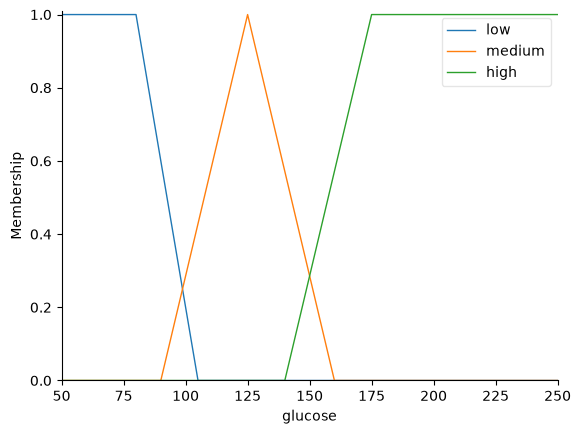

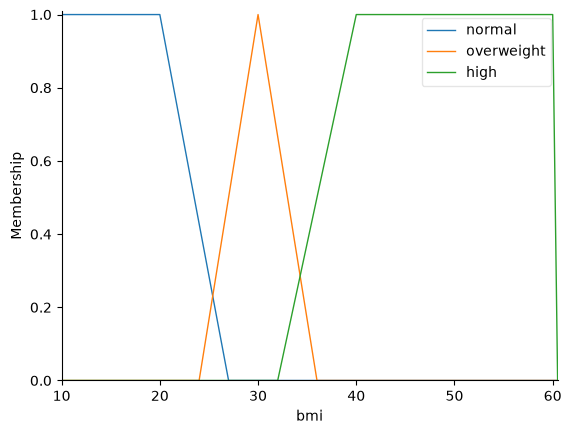

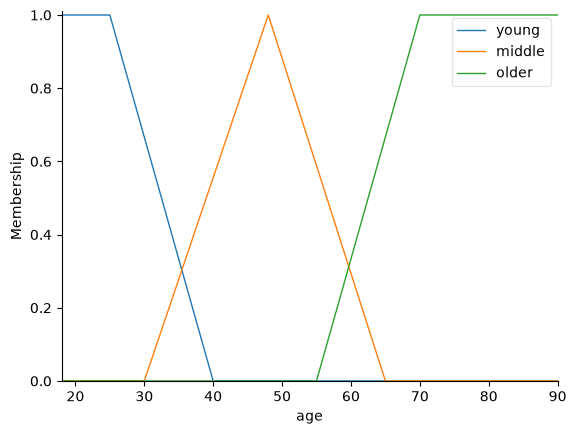

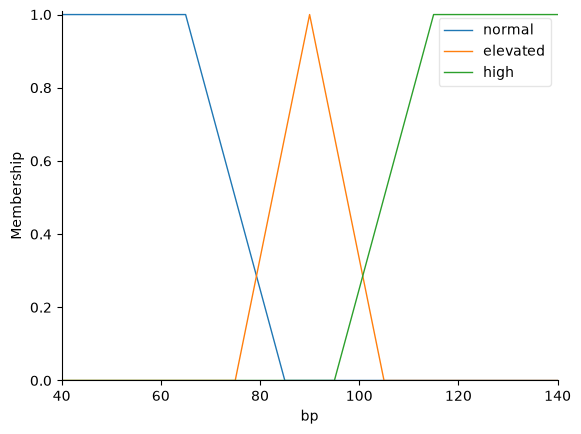

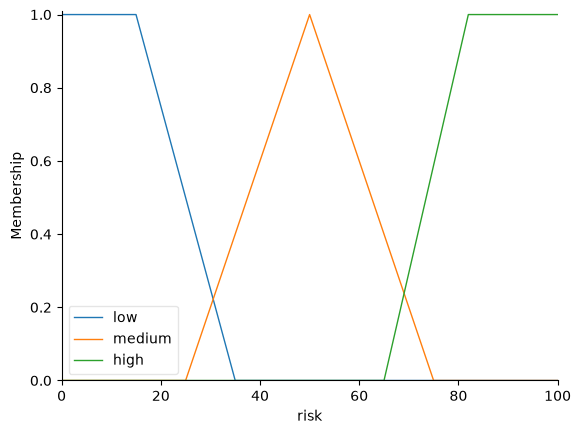

In [ ]:
glucose.view()
bmi.view()
age.view()
bp.view()
risk.view()
plt.show()

Функції належності сусідніх термів перекриваються, і саме тому одне значення часто належить двом термам. Перекриття: для `glucose` 90 – 105 (low і medium) та 140 – 160 (medium і high); для `bmi` 24 – 27 (normal і overweight) та 32 – 36 (overweight і high); для `age` 30 – 40 і 55 – 65; для `bp` 75 – 85 і 95 – 105; для `risk` 25 – 35 та 65 – 75. Крайні терми трапецієподібні з плато на межі універсуму (наприклад, `glucose` low дорівнює 1 для значень 50 – 80), а середні трикутні з єдиною вершиною. Вихідна змінна `risk` має три терми: low (плато 0 – 15), medium (вершина 50) і high (плато 82 – 100).

# Завдання 3. Профілі пацієнтів

> Перевірити систему мінімум на п'яти вручну сформованих профілях пацієнтів.

Risk score: 62.05829908304393


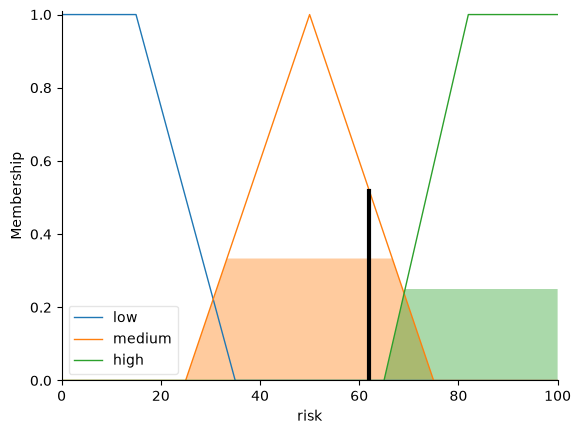

In [ ]:
sim = ctrl.ControlSystemSimulation(risk_system)

sim.input["glucose"] = 155
sim.input["bmi"] = 34
sim.input["age"] = 52
sim.input["bp"] = 88

sim.compute()

print("Risk score:", sim.output["risk"])
risk.view(sim=sim)
plt.show()

In [ ]:
def compute_risk(g, b, a, p):
    sim = ctrl.ControlSystemSimulation(risk_system)
    sim.input["glucose"] = np.clip(g, 50, 250)
    sim.input["bmi"] = np.clip(b, 10, 60)
    sim.input["age"] = np.clip(a, 18, 90)
    sim.input["bp"] = np.clip(p, 40, 140)
    try:
        sim.compute()
        return round(float(sim.output["risk"]), 6)
    except Exception:
        return np.nan

profiles = {
    "Молодий, здоровий": (85, 22, 23, 70),
    "Приклад із теорії": (155, 34, 52, 88),
    "Старший, усі фактори високі": (190, 42, 65, 110),
    "Глюкоза 95 (low/medium)": (95, 34, 55, 88),
    "Глюкоза 105 (low/medium)": (105, 34, 55, 88),
    "Глюкоза 140 (medium/high)": (140, 34, 55, 88),
    "Глюкоза 160 (medium/high)": (160, 34, 55, 88),
    "Глюкоза 120, BMI 38, 22 роки": (120, 38, 22, 70)
}

table = pd.DataFrame(
    [list(v) + [compute_risk(*v)] for v in profiles.values()],
    index=list(profiles.keys()),
    columns=["Glucose", "BMI", "Age", "BP", "Risk"]
)
print(table.round(2).to_string())

sweep = pd.DataFrame({
    "Glucose": np.arange(80, 201, 10),
    "Risk": [compute_risk(g, 34, 55, 88) for g in np.arange(80, 201, 10)]
}).set_index("Glucose")
print(sweep.round(2).T.to_string())

                              Glucose  BMI  Age   BP   Risk
Молодий, здоровий                  85   22   23   70  13.90
Приклад із теорії                 155   34   52   88  62.06
Старший, усі фактори високі       190   42   65  110  86.30
Глюкоза 95 (low/medium)            95   34   55   88  50.00
Глюкоза 105 (low/medium)          105   34   55   88  50.00
Глюкоза 140 (medium/high)         140   34   55   88  50.00
Глюкоза 160 (medium/high)         160   34   55   88  62.06
Глюкоза 120, BMI 38, 22 роки      120   38   22   70    NaN
Glucose   80    90    100   110   120   130   140    150    160    170    180    190    200
Risk     50.0  50.0  50.0  50.0  50.0  50.0  50.0  62.06  62.06  62.06  62.06  62.06  62.06


Приклад із теорії (155, 34, 52, 88) дає ризик 62.06: система відносить пацієнта до проміжної зони, ближчої до high. Молодий здоровий профіль (85, 22, 23, 70) дає 13.90 (low), а старший профіль із високими значеннями всіх факторів (190, 42, 65, 110) дає 86.30 (high), що відповідає очікуванню. Для перевірки меж сусідніх функцій змінювалась лише глюкоза (BMI 34, вік 55, тиск 88): значення 95, 105 і 140 дають по 50.00, а 160 дає 62.06. З таблиці розгортки глюкози видно, що ризик 50 тримається для значень 80 – 140, а потім стрибає до 62.06 і далі до 200 не змінюється. Причина в самій побудові: оператор AND це мінімум, тому ризик обмежений найслабшою умовою (BMI = 34 належить до high лише на 0.25), а коли спрацьовують лише правила з висновком medium, центроїд усіх цих випадків однаковий і дорівнює 50 незалежно від сили активації. Тобто поведінка логічна (ризик не зменшується із зростанням глюкози), але нечутлива до змін усередині плато. Профіль (120, 38, 22, 70) не активує жодного правила, тому ризик не визначений (NaN): у базі правил є прогалини для комбінацій, яких жодне правило не описує (високий BMI в молодому віці при середній глюкозі).

# Завдання 4. FuzzyRisk для всього датасету

> Розрахувати FuzzyRisk для датасету та оцінити BAcc і ROC-AUC.

In [ ]:
def fuzzy_risk(row):
    sim = ctrl.ControlSystemSimulation(risk_system)

    sim.input["glucose"] = np.clip(row["Glucose"], 50, 250)
    sim.input["bmi"] = np.clip(row["BMI"], 10, 60)
    sim.input["age"] = np.clip(row["Age"], 18, 90)
    sim.input["bp"] = np.clip(row["BloodPressure"], 40, 140)

    try:
        sim.compute()
        return sim.output["risk"]
    except Exception:
        return np.nan

raw_risk = df.apply(fuzzy_risk, axis=1)
near50 = raw_risk.notna() & (raw_risk - 50).abs().lt(1e-6)
print("Значень, що відрізняються від 50 менш ніж на 1e-6:", int(near50.sum()), ", з них точно 50:", int((raw_risk[near50] == 50).sum()))
print("Максимальне відхилення від 50 серед них:", float((raw_risk[near50] - 50).abs().max()))

df["FuzzyRisk"] = raw_risk.round(6)

print("Рядків без жодного активного правила:", df["FuzzyRisk"].isna().sum(), "з", len(df))
print(df.loc[df["FuzzyRisk"].isna(), "Outcome"].value_counts())

df_all = df.copy()
df = df.dropna(subset=["FuzzyRisk"]).copy()

print(df[["FuzzyRisk", "Outcome"]].head())
print(df.groupby("Outcome")["FuzzyRisk"].describe())
print("Частка значень рівно 50:", (df["FuzzyRisk"] == 50).mean())

Значень, що відрізняються від 50 менш ніж на 1e-6: 295 , з них точно 50: 23
Максимальне відхилення від 50 серед них: 4.973799150320701e-14
Рядків без жодного активного правила: 60 з 768
Outcome
0    39
1    21
Name: count, dtype: int64
   FuzzyRisk  Outcome
0  60.107889        1
1  14.706897        0
2  50.000000        1
3  14.538695        0
4  50.000000        1
         count       mean        std        min        25%        50%  \
Outcome                                                                 
0        461.0  37.520246  18.957991  13.166667  16.248269  42.645563   
1        247.0  58.956196  17.522465  13.398990  50.000000  50.000000   

               75%        max  
Outcome                        
0        50.000000  86.295597  
1        79.659237  86.295597  
Частка значень рівно 50: 0.4166666666666667


Для 60 із 768 пацієнтів (7.8%; 39 з класом 0 і 21 з класом 1) жодне правило не спрацювало, тому ризик не визначений, і далі вони виключені (залишилось 708 рядків). Для решти середній ризик 37.5 у класі 0 і 59.0 у класі 1, тобто в середньому система розрізняє класи. Важливий артефакт: 295 значень (41.7%) відрізняються від 50 менш ніж на 1e-6, і лише 23 з них точно дорівнюють 50, а решта відхиляється на величину до 5e-14, тобто на похибку обчислень. Це випадки, коли спрацьовують лише правила з висновком medium: центроїд обрізаного симетричного трикутника дорівнює 50 незалежно від рівня обрізання. Якщо порівнювати ці значення з порогом 50 без округлення, то рішення залежить від шуму округлення і може відрізнятися на різних платформах, тому ризик округлено до 6 знаків (тоді всі такі значення дорівнюють 50 і при `>= 50` відносяться до класу 1).

In [ ]:
threshold = 50
df["FuzzyPrediction"] = (df["FuzzyRisk"] >= threshold).astype(int)

fuzzy_bacc = balanced_accuracy_score(df["Outcome"], df["FuzzyPrediction"])
fuzzy_auc = roc_auc_score(df["Outcome"], df["FuzzyRisk"])

print("Fuzzy BAcc:", fuzzy_bacc)
print("Fuzzy ROC-AUC:", fuzzy_auc)
print(confusion_matrix(df["Outcome"], df["FuzzyPrediction"]))
print(classification_report(df["Outcome"], df["FuzzyPrediction"], digits=4))

Fuzzy BAcc: 0.7233614655694802
Fuzzy ROC-AUC: 0.7871068878603985
[[247 214]
 [ 22 225]]
              precision    recall  f1-score   support

           0     0.9182    0.5358    0.6767       461
           1     0.5125    0.9109    0.6560       247

    accuracy                         0.6667       708
   macro avg     0.7154    0.7234    0.6663       708
weighted avg     0.7767    0.6667    0.6695       708



Із порогом 50 fuzzy-система дає BAcc 0.7234 і ROC-AUC 0.7871. Матриця помилок: 247 з 461 здорових і 225 з 247 хворих класифіковано правильно (214 хибнопозитивних, 22 пропущені), чутливість 0.911, специфічність 0.536, точність (precision) для класу 1 0.5125. Тобто система майже не пропускає хворих, але половину здорових позначає як ризикових, і причина в тому, що 295 пацієнтів із ризиком рівно 50 усі потрапляють у клас 1 за умови `>= 50`. ROC-AUC (0.787) не залежить від порогу і показує помірну здатність упорядковувати пацієнтів за ризиком.

# Завдання 5. Залежність BAcc від порогу

> Побудувати залежність BAcc від decision threshold.

Best threshold: 46
Best BAcc: 0.7250959452694811


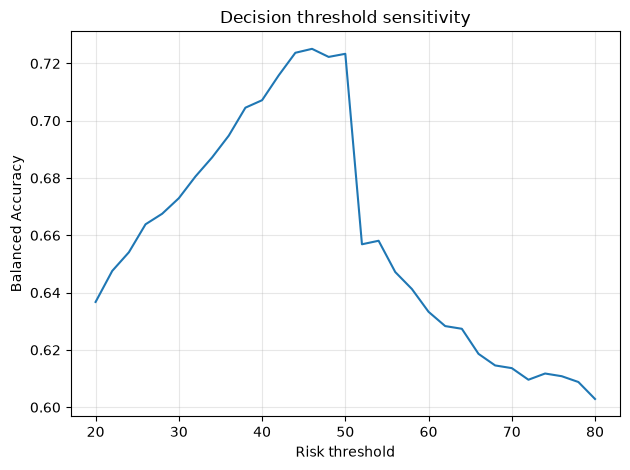

In [ ]:
thresholds = np.arange(20, 81, 2)
scores = []

for t in thresholds:
    pred = (df["FuzzyRisk"] >= t).astype(int)
    scores.append(balanced_accuracy_score(df["Outcome"], pred))

best_idx = np.argmax(scores)

print("Best threshold:", thresholds[best_idx])
print("Best BAcc:", scores[best_idx])

plt.plot(thresholds, scores)
plt.xlabel("Risk threshold")
plt.ylabel("Balanced Accuracy")
plt.title("Decision threshold sensitivity")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Залежність BAcc від порогу має пік 0.7251 при порозі 46 (на сітці 20 – 80 із кроком 2): від 20 до 46 BAcc зростає з 0.637 до 0.725, між 44 і 50 лишається на рівні 0.723 – 0.725, а після 50 різко падає (до 0.657 при 52) і далі поступово зменшується до 0.603 при 80. Різке падіння біля 50 пов'язане з тим, що 295 пацієнтів мають ризик 50, і поріг 50 – 52 відокремлює їх від решти. Найкращий поріг вибрано за тими самими даними, на яких оцінюється якість, тому 0.7251 трохи оптимістичний (у завданні 8 поріг вибирається на окремій навчальній частині). Різниця між порогами 44, 46 і 50 незначна (0.723 – 0.725), тому вибір порогу в цьому діапазоні практично не впливає на BAcc.

# Завдання 6. Decision surface

> Побудувати щонайменше одну 2D decision surface.

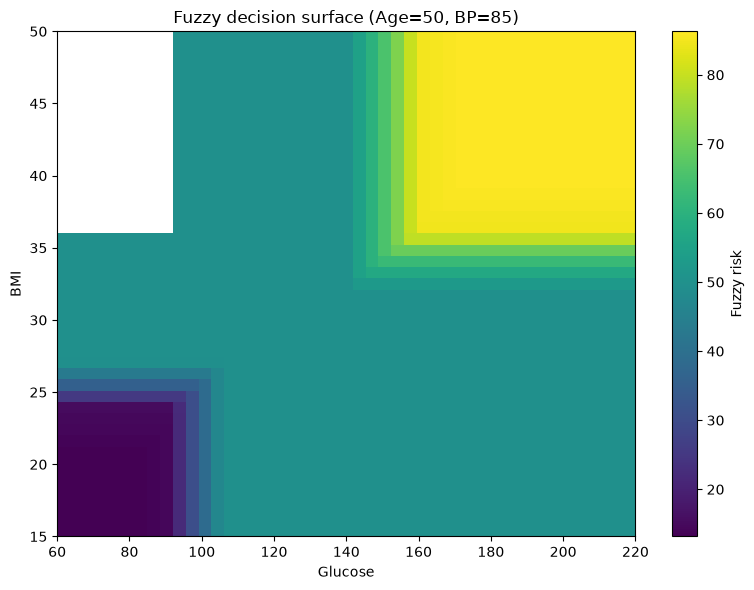

Точок без активних правил: 162 з 2025
Мінімум і максимум ризику: 13.166666666666671 86.29559748427674


In [ ]:
g_values = np.linspace(60, 220, 45)
b_values = np.linspace(15, 50, 45)
surface = np.zeros((len(b_values), len(g_values)))

for i, b in enumerate(b_values):
    for j, g in enumerate(g_values):
        sim = ctrl.ControlSystemSimulation(risk_system)
        sim.input["glucose"] = g
        sim.input["bmi"] = b
        sim.input["age"] = 50
        sim.input["bp"] = 85
        try:
            sim.compute()
            surface[i, j] = sim.output["risk"]
        except Exception:
            surface[i, j] = np.nan

plt.figure(figsize=(8, 6))
plt.imshow(
    surface, origin="lower", aspect="auto",
    extent=[g_values.min(), g_values.max(), b_values.min(), b_values.max()]
)
plt.colorbar(label="Fuzzy risk")
plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.title("Fuzzy decision surface (Age=50, BP=85)")
plt.tight_layout()
plt.show()

print("Точок без активних правил:", int(np.isnan(surface).sum()), "з", surface.size)
print("Мінімум і максимум ризику:", np.nanmin(surface), np.nanmax(surface))

Поверхня має східчасту структуру з трьох зон: велика область із ризиком близько 50 (проміжна зона), кут із низькою глюкозою та нормальним BMI з ризиком близько 13 – 15 (low) і кут з високою глюкозою (приблизно від 145) та високим BMI (приблизно від 32) з ризиком близько 86 (high); між зонами перехід швидкий. У проміжній області ризик майже не змінюється: збільшення BMI при глюкозі близько 100 – 140 не змінює ризик, бо лише правила з висновком medium дають однаковий центроїд. У лівому верхньому куті (глюкоза нижче приблизно 92, BMI вище 36) на малюнку порожньо: 162 із 2025 точок (8%) не активують жодного правила (при Age = 50, BP = 85). Мінімальний ризик на карті 13.17, максимальний 86.30, тобто виходи не заповнюють весь діапазон 0 – 100.

# Завдання 7. Експерименти

> Провести всі експерименти з розділу 17.

> 1. Membership functions: зсунути межі Glucose та BMI на ±5–10%. Що аналізувати: BAcc, ROC-AUC, форма decision surface.
> 2. Кількість linguistic terms: 2, 3 або 4 терми для Glucose. Що аналізувати: складність rules vs якість.
> 3. Rule ablation: послідовно вилучити 3–4 правила. Що аналізувати: які правила найбільше впливають на результат.
> 4. Decision threshold: 20–80. Що аналізувати: sensitivity метрик до порогу.
> 5. Додаткова ознака: додати DiabetesPedigreeFunction або Pregnancies. Що аналізувати: чи виправдане ускладнення системи.
> 6. Fuzzy vs Logistic Regression: ті самі ознаки. Що аналізувати: якість, інтерпретованість, характер помилок.

In [ ]:
UNI = {
    "glucose": np.arange(50, 251, 1),
    "bmi": np.arange(10, 61, 0.5),
    "age": np.arange(18, 91, 1),
    "bp": np.arange(40, 141, 1),
    "risk": np.arange(0, 101, 1),
    "pregnancies": np.arange(0, 18, 1),
    "dpf": np.arange(0.05, 2.51, 0.01)
}

INPUT_COLUMNS = {
    "glucose": "Glucose", "bmi": "BMI", "age": "Age", "bp": "BloodPressure",
    "pregnancies": "Pregnancies", "dpf": "DiabetesPedigreeFunction"
}

MF_BASE = {
    "glucose": {"low": ("trap", [50, 50, 80, 105]), "medium": ("tri", [90, 125, 160]), "high": ("trap", [140, 175, 250, 250])},
    "bmi": {"normal": ("trap", [10, 10, 20, 27]), "overweight": ("tri", [24, 30, 36]), "high": ("trap", [32, 40, 60, 60])},
    "age": {"young": ("trap", [18, 18, 25, 40]), "middle": ("tri", [30, 48, 65]), "older": ("trap", [55, 70, 90, 90])},
    "bp": {"normal": ("trap", [40, 40, 65, 85]), "elevated": ("tri", [75, 90, 105]), "high": ("trap", [95, 115, 140, 140])},
    "risk": {"low": ("trap", [0, 0, 15, 35]), "medium": ("tri", [25, 50, 75]), "high": ("trap", [65, 82, 100, 100])}
}

def R(out, *conds):
    return (conds, out)

RULES_BASE = [
    R("low", ("glucose", "low"), ("bmi", "normal")),
    R("low", ("glucose", "low"), ("age", "young")),
    R("low", ("glucose", "medium"), ("bmi", "normal"), ("age", "young")),
    R("medium", ("glucose", "medium"), ("bmi", "overweight")),
    R("medium", ("glucose", "medium"), ("age", "middle")),
    R("medium", ("bp", "elevated"), ("bmi", "overweight")),
    R("medium", ("glucose", "high"), ("bmi", "normal")),
    R("high", ("glucose", "high"), ("bmi", "high")),
    R("high", ("glucose", "high"), ("age", "older")),
    R("high", ("glucose", "high"), ("bp", "high")),
    R("high", ("bmi", "high"), ("age", "older")),
    R("high", ("glucose", "medium"), ("bmi", "high"), ("age", "older"))
]

def make_mf(kind, params, universe):
    return fuzz.trapmf(universe, params) if kind == "trap" else fuzz.trimf(universe, params)

def build_system(mf, rule_list):
    variables = {}
    for name, terms in mf.items():
        if name == "risk":
            variables[name] = ctrl.Consequent(UNI[name], name)
        else:
            variables[name] = ctrl.Antecedent(UNI[name], name)
        for term, (kind, params) in terms.items():
            variables[name][term] = make_mf(kind, params, UNI[name])
    built = []
    for conds, out in rule_list:
        antecedent = functools.reduce(operator.and_, [variables[v][t] for v, t in conds])
        built.append(ctrl.Rule(antecedent, variables["risk"][out]))
    return ctrl.ControlSystem(built)

def fuzzy_scores(system, frame):
    names = [a.label for a in system.antecedents]
    columns = {n: np.clip(frame[INPUT_COLUMNS[n]].to_numpy(float), UNI[n].min(), UNI[n].max()) for n in names}
    out = np.full(len(frame), np.nan)
    for k in range(len(frame)):
        sim = ctrl.ControlSystemSimulation(system)
        for n in names:
            sim.input[n] = columns[n][k]
        try:
            sim.compute()
            out[k] = round(float(sim.output["risk"]), 6)
        except Exception:
            pass
    return out

GRID = np.arange(20, 81, 2)

def summarize(scores, y, thr=50):
    mask = ~np.isnan(scores)
    pred = (scores[mask] >= thr).astype(int)
    full = np.zeros(len(y), int)
    full[mask] = pred
    curve = [balanced_accuracy_score(y[mask], (scores[mask] >= t).astype(int)) for t in GRID]
    return {
        "покрито": int(mask.sum()),
        "BAcc": balanced_accuracy_score(y[mask], pred),
        "ROC-AUC": roc_auc_score(y[mask], scores[mask]),
        "BAcc (усі 768)": balanced_accuracy_score(y, full),
        "найкращий поріг": int(GRID[int(np.argmax(curve))]),
        "BAcc при ньому": max(curve)
    }

def risk_surface(system, age_value=50, bp_value=85, n=45):
    g = np.linspace(60, 220, n)
    b = np.linspace(15, 50, n)
    gg, bb = np.meshgrid(g, b)
    frame = pd.DataFrame({"Glucose": gg.ravel(), "BMI": bb.ravel(), "Age": age_value, "BloodPressure": bp_value})
    return fuzzy_scores(system, frame).reshape(n, n)

def plot_surfaces(surfaces, titles):
    fig, axes = plt.subplots(1, len(surfaces), figsize=(5 * len(surfaces), 4.2), sharey=True)
    for ax, s, t in zip(np.atleast_1d(axes), surfaces, titles):
        im = ax.imshow(s, origin="lower", aspect="auto", extent=[60, 220, 15, 50], vmin=0, vmax=100)
        ax.set_title(t)
        ax.set_xlabel("Glucose")
    np.atleast_1d(axes)[0].set_ylabel("BMI")
    fig.colorbar(im, ax=axes, label="Fuzzy risk")
    plt.show()

y_all = df_all["Outcome"].to_numpy()
base_system = build_system(MF_BASE, RULES_BASE)
base_scores = fuzzy_scores(base_system, df_all)
check = np.nanmax(np.abs(base_scores - df_all["FuzzyRisk"].to_numpy()))
print("Максимальна різниця з системою із завдання 4:", check)
print("Базова система:", {k: round(v, 4) if isinstance(v, float) else v for k, v in summarize(base_scores, y_all).items()})

Максимальна різниця з системою із завдання 4: 0.0
Базова система: {'покрито': 708, 'BAcc': 0.7234, 'ROC-AUC': 0.7871, 'BAcc (усі 768)': 0.7058, 'найкращий поріг': 46, 'BAcc при ньому': 0.7251}


Для експериментів система збирається функцією `build_system` зі словника функцій належності та списку правил, що дозволяє змінювати окремі частини. Базові параметри відтворюють систему із завдання 4 (різниця в ризиках наведена вище). У рядках, де жодне правило не спрацювало, ризик не визначений, тому в таблицях наводиться кількість покритих рядків, BAcc та ROC-AUC на покритих рядках, а також BAcc по всіх 768 рядках, де непокритих пацієнтів віднесено до класу 0.

# Експеримент 1. Зсув меж функцій належності Glucose та BMI

      покрито    BAcc  ROC-AUC  BAcc (усі 768)  найкращий поріг  BAcc при ньому
-10%    662.0  0.6820   0.7925          0.6834             52.0          0.7220
-5%     694.0  0.7212   0.7948          0.7179             50.0          0.7212
+0%     708.0  0.7234   0.7871          0.7058             46.0          0.7251
+5%     712.0  0.7258   0.7889          0.7046             46.0          0.7344
+10%    718.0  0.7321   0.7913          0.7126             44.0          0.7360


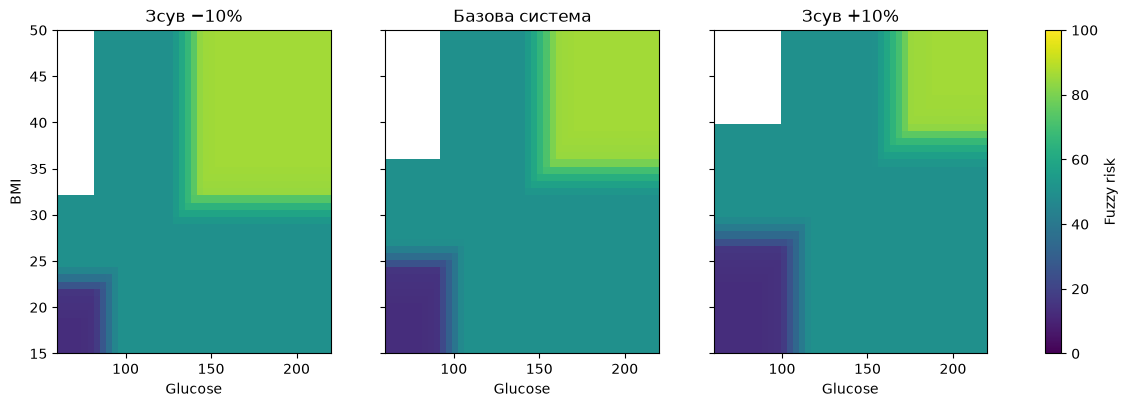

Точок без активних правил: [138, 162, 143]
Середній ризик на сітці: [59.39, 54.71, 50.31]


In [ ]:
def shift_mf(mf, names, delta):
    new = {k: {t: (kind, list(p)) for t, (kind, p) in v.items()} for k, v in mf.items()}
    for name in names:
        lo, hi = UNI[name].min(), UNI[name].max()
        for term, (kind, params) in new[name].items():
            new[name][term] = (kind, [p if p in (lo, hi) else round(p * (1 + delta), 4) for p in params])
    return new

exp1 = {}
exp1_scores = {}
for delta in [-0.10, -0.05, 0.0, 0.05, 0.10]:
    system = build_system(shift_mf(MF_BASE, ["glucose", "bmi"], delta), RULES_BASE)
    s = fuzzy_scores(system, df_all)
    exp1_scores[delta] = s
    exp1[f"{delta:+.0%}"] = summarize(s, y_all)

exp1_table = pd.DataFrame(exp1).T
print(exp1_table.round(4).to_string())

surfaces = [risk_surface(build_system(shift_mf(MF_BASE, ["glucose", "bmi"], d), RULES_BASE)) for d in [-0.10, 0.0, 0.10]]
plot_surfaces(surfaces, ["Зсув −10%", "Базова система", "Зсув +10%"])
print("Точок без активних правил:", [int(np.isnan(s).sum()) for s in surfaces])
print("Середній ризик на сітці:", [round(float(np.nanmean(s)), 2) for s in surfaces])

Зсув меж змінює метрики незначно і немонотонно: ROC-AUC 0.7925 (−10%), 0.7948 (−5%), 0.7871 (базова), 0.7889 (+5%), 0.7913 (+10%), тобто лежить у межах 0.787 – 0.795. BAcc при порозі 50 змінюється більше: 0.682, 0.721, 0.723, 0.726, 0.732, а найкращий поріг зсувається з 52 при −10% до 44 при +10%. Помітніше змінюється покриття: при зсуві −10% правила не спрацьовують для 106 пацієнтів (покрито 662), а при +10% лише для 50 (покрито 718). Decision surface при зсуві переміщається: при −10% зона high починається з нижчих значень глюкози та BMI, а зона low скорочується; при +10% навпаки, зона high зсувається вправо та вгору, а зона low розширюється; порожня область зміщується аналогічно. Середній ризик на сітці зменшується із зсувом вгору (59.4, 54.7, 50.3). Тобто ранжувальна здатність (ROC-AUC) стійка до такого зсуву, а рішення за фіксованим порогом і покриття чутливі до положення меж.

# Експеримент 2. Кількість linguistic terms для Glucose

                  правил  покрито    BAcc  ROC-AUC  BAcc (усі 768)  найкращий поріг  BAcc при ньому
2 терми              8.0    705.0  0.7360   0.7953          0.7036             46.0          0.7379
3 терми (базова)    12.0    708.0  0.7234   0.7871          0.7058             46.0          0.7251
4 терми             17.0    718.0  0.7038   0.7919          0.7104             50.0          0.7038


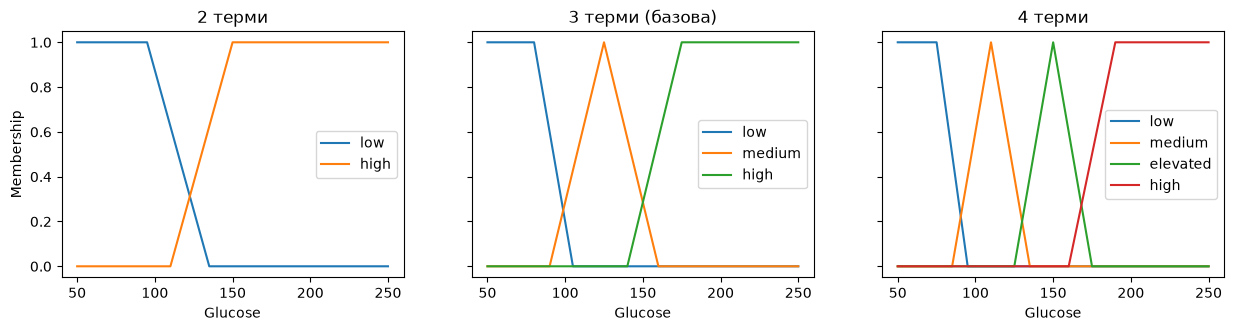

In [ ]:
mf2 = {k: dict(v) for k, v in MF_BASE.items()}
mf2["glucose"] = {"low": ("trap", [50, 50, 95, 135]), "high": ("trap", [110, 150, 250, 250])}
rules2 = [
    R("low", ("glucose", "low"), ("bmi", "normal")),
    R("low", ("glucose", "low"), ("age", "young")),
    R("medium", ("bp", "elevated"), ("bmi", "overweight")),
    R("medium", ("glucose", "high"), ("bmi", "normal")),
    R("high", ("glucose", "high"), ("bmi", "high")),
    R("high", ("glucose", "high"), ("age", "older")),
    R("high", ("glucose", "high"), ("bp", "high")),
    R("high", ("bmi", "high"), ("age", "older"))
]

mf4 = {k: dict(v) for k, v in MF_BASE.items()}
mf4["glucose"] = {
    "low": ("trap", [50, 50, 75, 95]),
    "medium": ("tri", [85, 110, 135]),
    "elevated": ("tri", [125, 150, 175]),
    "high": ("trap", [160, 190, 250, 250])
}
rules4 = [
    R("low", ("glucose", "low"), ("bmi", "normal")),
    R("low", ("glucose", "low"), ("age", "young")),
    R("low", ("glucose", "medium"), ("bmi", "normal"), ("age", "young")),
    R("medium", ("glucose", "medium"), ("bmi", "overweight")),
    R("medium", ("glucose", "medium"), ("age", "middle")),
    R("medium", ("bp", "elevated"), ("bmi", "overweight")),
    R("medium", ("glucose", "elevated"), ("bmi", "normal")),
    R("medium", ("glucose", "elevated"), ("bmi", "overweight")),
    R("medium", ("glucose", "elevated"), ("age", "middle")),
    R("high", ("glucose", "elevated"), ("bmi", "high")),
    R("high", ("glucose", "elevated"), ("age", "older")),
    R("high", ("glucose", "high"), ("bmi", "normal")),
    R("high", ("glucose", "high"), ("bmi", "overweight")),
    R("high", ("glucose", "high"), ("bmi", "high")),
    R("high", ("glucose", "high"), ("age", "older")),
    R("high", ("bmi", "high"), ("age", "older")),
    R("high", ("glucose", "medium"), ("bmi", "high"), ("age", "older"))
]

variants = {
    "2 терми": (mf2, rules2),
    "3 терми (базова)": (MF_BASE, RULES_BASE),
    "4 терми": (mf4, rules4)
}
exp2 = {}
exp2_scores = {}
for name, (m, r) in variants.items():
    s = fuzzy_scores(build_system(m, r), df_all)
    exp2_scores[name] = s
    exp2[name] = {"правил": len(r), **summarize(s, y_all)}

print(pd.DataFrame(exp2).T.round(4).to_string())

glucose_axis = np.arange(50, 251, 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2), sharey=True)
for ax, (name, (m, r)) in zip(axes, variants.items()):
    for term, (kind, params) in m["glucose"].items():
        ax.plot(glucose_axis, make_mf(kind, params, glucose_axis), label=term)
    ax.set_title(name)
    ax.set_xlabel("Glucose")
    ax.legend()
axes[0].set_ylabel("Membership")
plt.show()

При 2, 3 і 4 термах для Glucose (8, 12 і 17 правил) ROC-AUC становить 0.7953, 0.7871 і 0.7919, а BAcc при порозі 50 дорівнює 0.7360, 0.7234 і 0.7038. Покрито 705, 708 і 718 пацієнтів; BAcc по всіх 768 пацієнтах 0.7036, 0.7058 і 0.7104. Тобто різниці дуже малі (ROC-AUC відрізняється менш ніж на 0.01), немонотонні, і складніша система з 17 правилами не дає кращої якості, а проста система з 8 правилами не гірша. Таким чином, збільшення кількості термів і правил підвищує складність і трохи покриття, але не підвищує якості, тож на цих даних 2 терми достатньо. Правила для варіантів з 2 і 4 термами складено мною, тому результат залежить також від того, як вони складені.

# Експеримент 3. Rule ablation

In [ ]:
rows = []
for i in range(len(RULES_BASE)):
    s = fuzzy_scores(build_system(MF_BASE, RULES_BASE[:i] + RULES_BASE[i + 1:]), df_all)
    rows.append({"вилучено правило": i + 1, **summarize(s, y_all)})

ablation = pd.DataFrame(rows).set_index("вилучено правило")
base_row = summarize(base_scores, y_all)
ablation["ΔBAcc"] = ablation["BAcc"] - base_row["BAcc"]
ablation["ΔROC-AUC"] = ablation["ROC-AUC"] - base_row["ROC-AUC"]
ablation["Δпокриття"] = ablation["покрито"] - base_row["покрито"]
print(ablation[["покрито", "BAcc", "ROC-AUC", "BAcc (усі 768)", "ΔBAcc", "ΔROC-AUC", "Δпокриття"]].round(4).to_string())

                  покрито    BAcc  ROC-AUC  BAcc (усі 768)   ΔBAcc  ΔROC-AUC  Δпокриття
вилучено правило                                                                       
1                     705  0.7197   0.7844          0.7038 -0.0037   -0.0027         -3
2                     634  0.6571   0.7492          0.6764 -0.0663   -0.0379        -74
3                     693  0.6791   0.7602          0.6712 -0.0443   -0.0269        -15
4                     627  0.7564   0.8099          0.7180  0.0330    0.0228        -81
5                     653  0.7352   0.8014          0.6834  0.0119    0.0143        -55
6                     697  0.7260   0.7909          0.7024  0.0026    0.0038        -11
7                     699  0.7232   0.7891          0.6947 -0.0001    0.0020         -9
8                     642  0.7208   0.7374          0.6256 -0.0026   -0.0497        -66
9                     706  0.7230   0.7867          0.7020 -0.0004   -0.0004         -2
10                    707  0.723

Найбільший вплив має правило 8 (glucose high AND bmi high → high): без нього ROC-AUC падає з 0.7871 до 0.7374 (−0.050), покриття на 66 пацієнтів, а BAcc по всіх 768 з 0.7058 до 0.6256. Далі правило 2 (glucose low AND age young → low; ΔROC-AUC −0.038, покриття −74) і правило 3 (ΔROC-AUC −0.027). Правила 9, 10 і 11 майже не впливають (зміни ROC-AUC не більші за 0.0015 за модулем), а правило 12 не змінює жодної метрики. Неочікувано, вилучення правил 4 і 5 (обидва з висновком medium) покращує ROC-AUC (+0.023 і +0.014) та BAcc, але це супроводжується втратою покриття на 81 і 55 пацієнтів, тому результат на покритій частині не можна порівнювати прямо; BAcc по всіх 768 для правила 4 зростає з 0.7058 до 0.7180, а для правила 5 падає до 0.6834, тож однозначно сказати про користь від вилучення цих правил не можна.

In [ ]:
order = list((ablation["ΔROC-AUC"]).sort_values().index[:4])
print("Порядок вилучення (за найбільшою втратою ROC-AUC):", order)

cum_rows = [{"вилучені правила": "—", "правил": len(RULES_BASE), **base_row}]
removed = []
for i in order:
    removed.append(i)
    kept = [r for k, r in enumerate(RULES_BASE, start=1) if k not in removed]
    s = fuzzy_scores(build_system(MF_BASE, kept), df_all)
    cum_rows.append({"вилучені правила": ", ".join(map(str, removed)), "правил": len(kept), **summarize(s, y_all)})

print(pd.DataFrame(cum_rows).set_index("вилучені правила").round(4).to_string())

Порядок вилучення (за найбільшою втратою ROC-AUC): [8, 2, 3, 1]


                  правил  покрито    BAcc  ROC-AUC  BAcc (усі 768)  найкращий поріг  BAcc при ньому
вилучені правила                                                                                   
—                     12      708  0.7234   0.7871          0.7058               46          0.7251
8                     11      642  0.7208   0.7374          0.6256               46          0.7240
8, 2                  10      568  0.6609   0.6765          0.5963               50          0.6609
8, 2, 3                9      553  0.6041   0.6234          0.5617               50          0.6041
8, 2, 3, 1             8      503  0.5000   0.5267          0.5357               54          0.5283


Послідовне вилучення чотирьох правил (8, 2, 3, 1; обрано за найбільшою втратою ROC-AUC) монотонно погіршує систему: ROC-AUC 0.7871, 0.7374, 0.6765, 0.6234 і 0.5267, а BAcc 0.7234, 0.7208, 0.6609, 0.6041 і 0.5000. Покриття падає з 708 до 503 пацієнтів. Після вилучення чотирьох правил залишається 8, ROC-AUC (0.527) близький до випадкового вгадування (0.5), а BAcc дорівнює 0.5000, тобто система стає марною. Це показує, що якість забезпечують правила, які поєднують високу глюкозу з іншими факторами, і низькоглюкозні правила.

# Експеримент 4. Decision threshold 20–80

             BAcc  sensitivity  specificity  positive rate
threshold                                                 
20         0.6367       0.9676       0.3059         0.7895
26         0.6638       0.9676       0.3601         0.7542
32         0.6806       0.9555       0.4056         0.7203
38         0.7046       0.9514       0.4577         0.6850
44         0.7237       0.9312       0.5163         0.6398
50         0.7234       0.9109       0.5358         0.6201
56         0.6472       0.3725       0.9219         0.1808
62         0.6283       0.3239       0.9328         0.1568
68         0.6146       0.2834       0.9458         0.1342
74         0.6118       0.2713       0.9523         0.1257
80         0.6029       0.2470       0.9588         0.1130


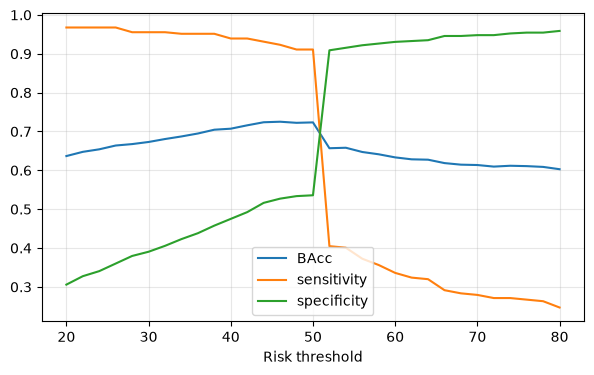

Унікальних значень FuzzyRisk: 242
50.000    295
13.167     19
14.707     11
86.296     11
15.586      7
Name: count, dtype: int64


In [ ]:
y_cov = df["Outcome"].to_numpy()
s_cov = df["FuzzyRisk"].to_numpy()

rows = []
for t in GRID:
    pred = (s_cov >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_cov, pred).ravel()
    rows.append({"threshold": t, "BAcc": balanced_accuracy_score(y_cov, pred), "sensitivity": tp / (tp + fn),
                 "specificity": tn / (tn + fp), "positive rate": pred.mean()})

thr_table = pd.DataFrame(rows).set_index("threshold")
print(thr_table.iloc[::3].round(4).to_string())

plt.figure(figsize=(7, 4))
plt.plot(thr_table.index, thr_table["BAcc"], label="BAcc")
plt.plot(thr_table.index, thr_table["sensitivity"], label="sensitivity")
plt.plot(thr_table.index, thr_table["specificity"], label="specificity")
plt.xlabel("Risk threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Унікальних значень FuzzyRisk:", len(np.unique(s_cov.round(6))))
print(pd.Series(s_cov.round(3)).value_counts().head(5))

При порогах до 50 чутливість висока (0.968 при 20, 0.931 при 44, 0.911 при 50), а специфічність низька (0.306, 0.516, 0.536), тобто система позначає більшість пацієнтів як ризикових. На порозі між 50 і 56 чутливість різко падає (до 0.373 при 56) і специфічність зростає (до 0.922), а далі до порогу 80 чутливість зменшується до 0.247 при специфічності 0.959. Частка пацієнтів, віднесених до класу 1, змінюється від 0.790 (поріг 20) до 0.620 (50), 0.181 (56) і 0.113 (80). Таке різке падіння пояснюється кластером із 295 значень рівно 50 (з 242 унікальних значень ризику): поріг фактично має лише два режими, до і після плато. Тому метрики чутливі до порогу, а BAcc залишається найвищим (0.723 – 0.725) лише в вузькому діапазоні 44 – 50.

# Експеримент 5. Додаткова ознака

In [ ]:
mf5p = {k: dict(v) for k, v in MF_BASE.items()}
mf5p["pregnancies"] = {"few": ("trap", [0, 0, 1, 3]), "many": ("trap", [3, 6, 17, 17])}
rules5p = RULES_BASE + [
    R("low", ("pregnancies", "few"), ("glucose", "low")),
    R("medium", ("pregnancies", "many"), ("glucose", "medium")),
    R("high", ("pregnancies", "many"), ("glucose", "high"))
]

mf5d = {k: dict(v) for k, v in MF_BASE.items()}
mf5d["dpf"] = {"low": ("trap", [0.05, 0.05, 0.25, 0.45]), "high": ("trap", [0.35, 0.8, 2.5, 2.5])}
rules5d = RULES_BASE + [
    R("low", ("dpf", "low"), ("glucose", "low")),
    R("medium", ("dpf", "high"), ("glucose", "medium")),
    R("high", ("dpf", "high"), ("glucose", "high"))
]

variants5 = {
    "базова (4 входи)": (MF_BASE, RULES_BASE),
    "+ Pregnancies": (mf5p, rules5p),
    "+ DiabetesPedigreeFunction": (mf5d, rules5d)
}
exp5 = {}
for name, (m, r) in variants5.items():
    s = fuzzy_scores(build_system(m, r), df_all)
    exp5[name] = {"правил": len(r), **summarize(s, y_all)}

print(pd.DataFrame(exp5).T.round(4).to_string())
print(df_all.groupby("Outcome")[["Pregnancies", "DiabetesPedigreeFunction"]].mean().round(3))

                            правил  покрито    BAcc  ROC-AUC  BAcc (усі 768)  найкращий поріг  BAcc при ньому
базова (4 входи)              12.0    708.0  0.7234   0.7871          0.7058             46.0          0.7251
+ Pregnancies                 15.0    718.0  0.7214   0.7988          0.7122             46.0          0.7230
+ DiabetesPedigreeFunction    15.0    741.0  0.7278   0.8003          0.7207             50.0          0.7278
         Pregnancies  DiabetesPedigreeFunction
Outcome                                       
0              3.298                      0.43
1              4.866                      0.55


Додавання Pregnancies (3 нові правила) дає ROC-AUC 0.7988 проти 0.7871, а DiabetesPedigreeFunction (3 нові правила) дає 0.8003; BAcc при порозі 50 при цьому 0.7214 і 0.7278 проти 0.7234, а BAcc по всіх 768 пацієнтах 0.7122 і 0.7207 проти 0.7058. Покриття зростає з 708 до 718 і 741 пацієнта. Тобто приріст ROC-AUC близько 0.012 – 0.013 і BAcc по всіх до 0.015, але частково пов'язаний із розширенням покриття (нові правила активуються там, де раніше не спрацьовував жоден). Обидві ознаки в середньому вищі в класі 1 (Pregnancies 4.87 проти 3.30, DiabetesPedigreeFunction 0.55 проти 0.43), що узгоджується з напрямком доданих правил. Ускладнення (на 25% більше правил, ще одна змінна з власними функціями) дає невеликий приріст, який у межах цього експерименту не підтверджений повторними вимірюваннями, і одночасно ускладнює пояснення, тому виправданість залежить від того, чи важлива така різниця.

# Експеримент 6. Fuzzy vs Logistic Regression

Цей експеримент збігається із завданням 8 і виконується в ньому.

# Завдання 8. Fuzzy system та Logistic Regression

> Порівняти fuzzy system з Logistic Regression.

Обидві моделі оцінюються на одній і тій самій тестовій частині (25%, `random_state = 42`, стратифікація). Поріг fuzzy-системи вибирається лише на навчальній частині.

In [ ]:
X = df[features]
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=2000))
])

model.fit(X_train, y_train)
pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]

print("LogReg BAcc:", balanced_accuracy_score(y_test, pred))
print("LogReg ROC-AUC:", roc_auc_score(y_test, prob))
print(confusion_matrix(y_test, pred))

fz_train = df.loc[X_train.index, "FuzzyRisk"]
fz_test = df.loc[X_test.index, "FuzzyRisk"]

train_curve = [balanced_accuracy_score(y_train, (fz_train >= t).astype(int)) for t in GRID]
thr_train = int(GRID[int(np.argmax(train_curve))])
print("Поріг, вибраний на навчальній частині:", thr_train)

def report(name, y_true, predicted, score):
    tn, fp, fn, tp = confusion_matrix(y_true, predicted).ravel()
    return {"BAcc": balanced_accuracy_score(y_true, predicted), "ROC-AUC": roc_auc_score(y_true, score),
            "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp), "FP": fp, "FN": fn}

comparison = pd.DataFrame({
    "Fuzzy, поріг 50": report("f50", y_test, (fz_test >= 50).astype(int), fz_test),
    f"Fuzzy, поріг {thr_train}": report("ft", y_test, (fz_test >= thr_train).astype(int), fz_test),
    "Logistic Regression": report("lr", y_test, pred, prob)
}).T
print(comparison.round(4).to_string())

coef = pd.Series(model.named_steps["clf"].coef_[0], index=features)
print("Коефіцієнти логістичної регресії (стандартизовані ознаки):")
print(coef.round(3).to_string())
print("Спірмен між FuzzyRisk і ймовірністю LogReg на тесті:", spearmanr(fz_test, prob).correlation)

LogReg BAcc: 0.7269985974754558
LogReg ROC-AUC: 0.8559607293127629
[[106   9]
 [ 29  33]]
Поріг, вибраний на навчальній частині: 44
                       BAcc  ROC-AUC  sensitivity  specificity    FP    FN
Fuzzy, поріг 50      0.7373   0.7863       0.9355       0.5391  53.0   4.0
Fuzzy, поріг 44      0.7156   0.7863       0.9355       0.4957  58.0   4.0
Logistic Regression  0.7270   0.8560       0.5323       0.9217   9.0  29.0
Коефіцієнти логістичної регресії (стандартизовані ознаки):
Glucose          0.877
BMI              0.772
Age              0.248
BloodPressure    0.082
Спірмен між FuzzyRisk і ймовірністю LogReg на тесті: 0.7789189058200137


На тестовій частині (177 пацієнтів: 115 здорових і 62 хворих) Logistic Regression має BAcc 0.7270 і ROC-AUC 0.8560, а fuzzy-система з порогом 50 дає BAcc 0.7373 і ROC-AUC 0.7863; поріг, вибраний на навчальній частині (44), дає BAcc 0.7156. За BAcc fuzzy-система не поступається (різниця близько одного пацієнта в класі хворих), але за ROC-AUC, який не залежить від порогу, Logistic Regression кращий на 0.07, тобто краще впорядковує пацієнтів за ризиком. Характер помилок протилежний: fuzzy-система майже не пропускає хворих (чутливість 0.936, 4 пропущених), але має 53 хибнопозитивних (специфічність 0.539), а Logistic Regression з порогом 0.5 має специфічність 0.922 (9 хибнопозитивних), але пропускає 29 хворих (чутливість 0.532). Спірмен між оцінками двох моделей 0.78, тому вони упорядковують пацієнтів досить схоже. Інтерпретованість різна: у Logistic Regression вона дається коефіцієнтами (Glucose 0.877, BMI 0.772, Age 0.248, BloodPressure 0.082 на стандартизованих ознаках), у fuzzy-системи правилами та функціями належності. Різниця у BAcc між порогом 44 і 50 для fuzzy-системи (0.716 проти 0.737) показує, що на тесті з 177 пацієнтів такі різниці в межах шуму.

# Завдання 9. Розбіжності між fuzzy system та Logistic Regression

> Виділити 3–5 прикладів, де fuzzy system і baseline дають різні рішення, та пояснити причину.

In [ ]:
def rule_strengths(mf, rule_list, frame):
    cols = {}
    for name in ["glucose", "bmi", "age", "bp"]:
        cols[name] = np.clip(frame[INPUT_COLUMNS[name]].to_numpy(float), UNI[name].min(), UNI[name].max())
    memberships = {}
    for name in cols:
        for term, (kind, params) in mf[name].items():
            memberships[(name, term)] = np.interp(cols[name], UNI[name], make_mf(kind, params, UNI[name]))
    out = np.zeros((len(frame), len(rule_list)))
    for j, (conds, _) in enumerate(rule_list):
        out[:, j] = np.min([memberships[c] for c in conds], axis=0)
    return out

test_frame = df.loc[X_test.index, features + ["Outcome", "FuzzyRisk"]].copy()
test_frame["LogRegProb"] = prob
test_frame["FuzzyPred"] = (test_frame["FuzzyRisk"] >= 50).astype(int)
test_frame["LogRegPred"] = pred
strength = rule_strengths(MF_BASE, RULES_BASE, test_frame)
test_frame["top_rule"] = [int(np.argmax(r)) + 1 for r in strength]
test_frame["top_strength"] = strength.max(axis=1).round(2)

differ = test_frame[test_frame["FuzzyPred"] != test_frame["LogRegPred"]].copy()
print("Кількість розбіжностей:", len(differ), "з", len(test_frame))
print("Fuzzy правильний, LogReg помиляється:", int(((differ["FuzzyPred"] == differ["Outcome"])).sum()))
print("LogReg правильний, fuzzy помиляється:", int(((differ["LogRegPred"] == differ["Outcome"])).sum()))

differ["tie"] = np.isclose(differ["FuzzyRisk"], 50)
print("Розбіжностей, де FuzzyRisk дорівнює 50:", int(differ["tie"].sum()))
print(differ.groupby(["FuzzyPred", "LogRegPred"]).size())

fuzzy_right = differ[differ["FuzzyPred"] == differ["Outcome"]].sort_values("top_strength", ascending=False).head(2)
logreg_wrong_tie = differ[(differ["LogRegPred"] == differ["Outcome"]) & differ["tie"]].sort_values("top_strength", ascending=False).head(2)
logreg_wrong_other = differ[(differ["LogRegPred"] == differ["Outcome"]) & ~differ["tie"]].assign(
    dist=lambda d: (d["FuzzyRisk"] - 50).abs()).sort_values("dist", ascending=False).head(1).drop(columns="dist")
examples = pd.concat([fuzzy_right, logreg_wrong_tie, logreg_wrong_other])
print(examples[features + ["Outcome", "FuzzyRisk", "LogRegProb", "top_rule", "top_strength"]].round(2).to_string())

Кількість розбіжностей: 69 з 177
Fuzzy правильний, LogReg помиляється: 25
LogReg правильний, fuzzy помиляється: 44
Розбіжностей, де FuzzyRisk дорівнює 50: 66
FuzzyPred  LogRegPred
1          0             69
dtype: int64
     Glucose   BMI  Age  BloodPressure  Outcome  FuzzyRisk  LogRegProb  top_rule  top_strength
695    142.0  30.4   43           90.0        1      50.00        0.47         6          0.93
468    120.0  30.0   38           72.0        1      50.00        0.26         4          0.86
460    120.0  20.8   48           72.0        0      50.00        0.13         5          0.86
449    120.0  30.5   26           74.0        0      50.00        0.23         4          0.86
28     145.0  22.2   57           82.0        0      56.39        0.32         5          0.43


Моделі дають різні рішення для 69 із 177 тестових пацієнтів (39%), і всі розбіжності мають один напрям: fuzzy-система позначає як ризикових, а Logistic Regression ні. У 25 випадках fuzzy правильний (це хворі, яких пропустила LogReg), у 44 помиляється (здорові, яких вона позначила як ризикових). У 66 із 69 розбіжностей FuzzyRisk дорівнює 50, тобто пацієнт потрапляє в клас 1 лише через те, що поріг застосовано як `>= 50`, а єдина спрацьована група правил має висновок medium. Нижче наведено п'ять прикладів: два, де fuzzy правильний, і три, де правильна Logistic Regression.

In [ ]:
for idx, row in examples.iterrows():
    k = int(row["top_rule"]) - 1
    conds, out = RULES_BASE[k]
    text = " AND ".join(f"{v} {t}" for v, t in conds)
    fired = [(j + 1, round(float(s), 2)) for j, s in enumerate(rule_strengths(MF_BASE, RULES_BASE, test_frame.loc[[idx]])[0]) if s > 0]
    print(f"Пацієнт {idx}: Outcome = {int(row['Outcome'])}, FuzzyRisk = {row['FuzzyRisk']:.1f}, LogReg = {row['LogRegProb']:.2f}")
    print("  Glucose =", row["Glucose"], ", BMI =", row["BMI"], ", Age =", row["Age"], ", BP =", row["BloodPressure"])
    print("  Активні правила (номер, сила):", fired)

Пацієнт 695: Outcome = 1, FuzzyRisk = 50.0, LogReg = 0.47
  Glucose = 142.0 , BMI = 30.4 , Age = 43 , BP = 90.0
  Активні правила (номер, сила): [(4, 0.51), (5, 0.51), (6, 0.93)]
Пацієнт 468: Outcome = 1, FuzzyRisk = 50.0, LogReg = 0.26
  Glucose = 120.0 , BMI = 30.0 , Age = 38 , BP = 72.0
  Активні правила (номер, сила): [(4, 0.86), (5, 0.44)]
Пацієнт 460: Outcome = 0, FuzzyRisk = 50.0, LogReg = 0.13
  Glucose = 120.0 , BMI = 20.8 , Age = 48 , BP = 72.0
  Активні правила (номер, сила): [(5, 0.86)]
Пацієнт 449: Outcome = 0, FuzzyRisk = 50.0, LogReg = 0.23
  Glucose = 120.0 , BMI = 30.5 , Age = 26 , BP = 74.0
  Активні правила (номер, сила): [(4, 0.86)]
Пацієнт 28: Outcome = 0, FuzzyRisk = 56.4, LogReg = 0.32
  Glucose = 145.0 , BMI = 22.2 , Age = 57 , BP = 82.0
  Активні правила (номер, сила): [(5, 0.43), (7, 0.14), (9, 0.13)]


Приклади, де fuzzy правильний (обидва хворі): пацієнт 695 (Glucose 142, BMI 30.4, Age 43, BP 90) спрацьовує за правилами 4, 5 і 6 (сила 0.51, 0.51 і 0.93), усі з висновком medium, тому ризик 50 і рішення «хворий», а LogReg дає 0.47, що трохи нижче 0.5. Пацієнт 468 (120, 30.0, 38, 72) активує правила 4 (0.86) та 5 (0.44) і також отримує 50, тоді як LogReg дає 0.26: проміжна глюкоза з надмірною вагою fuzzy-система вважає ризиковою, а логістична модель оцінює ймовірність низькою. Приклади, де правильна LogReg (обидва здорові): пацієнти 460 (120, 20.8, 48, 72), 449 (120, 30.5, 26, 74) отримують ризик 50 через єдине правило 5 або 4 із силою 0.86, і LogReg дає 0.13 та 0.23. Пацієнт 28 (145, 22.2, 57, 82) отримує 56.4 через правила 5, 7 і 9 із силою 0.43, 0.14 і 0.13, LogReg дає 0.32. Спільна причина: Mamdani із центроїдом дає 50 для будь-якої сили активації тільки правил medium (0.44 чи 0.86 дає те саме значення), а поріг 50 включає цей рівень у позитивний клас, тоді як logistic regression безперервно враховує значення глюкози (у цих прикладах глюкоза 120 разом з іншими ознаками дає низьку ймовірність). Тобто головна відмінність у тому, що fuzzy-система втрачає інформацію про те, наскільки сильно спрацювало правило, а LogReg її зберігає.

# Завдання 10. Переваги та обмеження knowledge-driven fuzzy approach

> Сформулювати висновок про переваги та обмеження knowledge-driven fuzzy approach.

**Переваги.** Кожне рішення прозоре: для будь-якого пацієнта можна вивести правила, що спрацювали, і їхню силу (так зроблено в завданні 9), а межі функцій належності та самі правила можна прочитати й обговорити з експертом. Побудова системи не потребує розмітки, і навіть без жодного навчання вона розрізняє класи (ROC-AUC 0.787 проти 0.856 для Logistic Regression на тому самому тесті). Нечіткі межі дозволяють уникнути жорстких порогів, а поведінку можна передбачити за правилами.

**Обмеження.** Якість визначається суб'єктивним вибором меж функцій і правил: зсув меж на 10% змінює покриття на кілька десятків пацієнтів і положення порогів, а вилучення одного правила (8) знижує ROC-AUC на 0.05. База правил має прогалини: для 60 пацієнтів (7.8%) жодне правило не спрацювало. Втрата інформації через дефазифікацію: коли активні лише правила medium, ризик завжди 50 (41.7% пацієнтів), тому система не розрізняє слабку й сильну активацію, а рішення за порогом 50 різко змінюється біля цього значення. Fuzzy-система дає гіршу ранжувальну здатність, ніж Logistic Regression, а розширення правил (Pregnancies, DiabetesPedigreeFunction, 4 терми) вимагає ручної роботи й не дає суттєвого приросту. Клінічної валідації немає, а межі є навчальною конфігурацією, тому результати не придатні для діагностики.

# Додаткове завдання підвищеної складності

> Оберіть один варіант: (1) автоматично оптимізуйте параметри membership functions за допомогою Genetic Algorithm або PSO з попередніх практикумів; (2) реалізуйте Sugeno-подібний вихід та порівняйте його з Mamdani; (3) побудуйте простий neuro-fuzzy/ANFIS prototype за доступною Python-реалізацією та порівняйте ручні правила з data-driven adaptation.

Обрано варіант (2).

Покрито Sugeno: 708 , Mamdani: 708 , збігаються: True
                       покрито    BAcc  ROC-AUC  BAcc (усі 768)  найкращий поріг  BAcc при ньому  час, с
Mamdani                  708.0  0.7234   0.7871          0.7058             46.0          0.7251  1.1166
Sugeno (0-го порядку)    708.0  0.7234   0.7850          0.7058             46.0          0.7262  0.0009
Спірмен між оцінками: 0.9949354423301104
Унікальних значень: Mamdani 242 , Sugeno 167


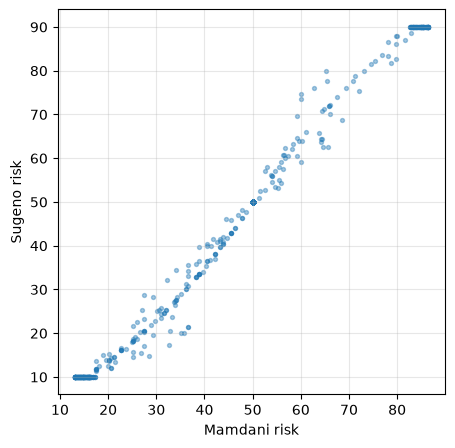

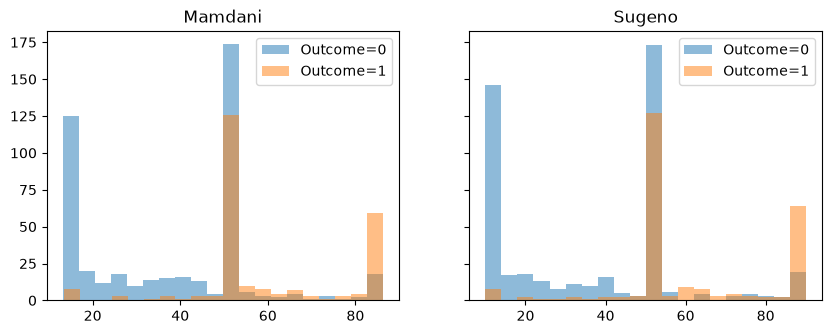

In [ ]:
CONSTANTS = {"low": 10.0, "medium": 50.0, "high": 90.0}

def sugeno_scores(mf, rule_list, frame):
    strength = rule_strengths(mf, rule_list, frame)
    z = np.array([CONSTANTS[out] for _, out in rule_list])
    total = strength.sum(axis=1)
    out = np.full(len(frame), np.nan)
    ok = total > 0
    out[ok] = ((strength[ok] * z).sum(axis=1) / total[ok]).round(6)
    return out

t0 = time.time()
sugeno_all = sugeno_scores(MF_BASE, RULES_BASE, df_all)
t_sugeno = time.time() - t0

t0 = time.time()
mamdani_all = fuzzy_scores(base_system, df_all)
t_mamdani = time.time() - t0

both = ~np.isnan(sugeno_all) & ~np.isnan(mamdani_all)
print("Покрито Sugeno:", int((~np.isnan(sugeno_all)).sum()), ", Mamdani:", int((~np.isnan(mamdani_all)).sum()), ", збігаються:", bool((np.isnan(sugeno_all) == np.isnan(mamdani_all)).all()))

result = pd.DataFrame({
    "Mamdani": summarize(mamdani_all, y_all),
    "Sugeno (0-го порядку)": summarize(sugeno_all, y_all)
}).T
result["час, с"] = [t_mamdani, t_sugeno]
print(result.round(4).to_string())
print("Спірмен між оцінками:", spearmanr(sugeno_all[both], mamdani_all[both]).correlation)
print("Унікальних значень: Mamdani", len(np.unique(mamdani_all[both].round(6))), ", Sugeno", len(np.unique(sugeno_all[both].round(6))))

plt.figure(figsize=(5, 5))
plt.scatter(mamdani_all[both], sugeno_all[both], s=8, alpha=0.4)
plt.xlabel("Mamdani risk")
plt.ylabel("Sugeno risk")
plt.grid(alpha=0.3)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, (name, s) in zip(axes, [("Mamdani", mamdani_all), ("Sugeno", sugeno_all)]):
    for cls in [0, 1]:
        ax.hist(s[(y_all == cls) & ~np.isnan(s)], bins=20, alpha=0.5, label=f"Outcome={cls}")
    ax.set_title(name)
    ax.legend()
plt.show()

Sugeno-подібна система нульового порядку використовує ті самі функції належності та правила, але висновок кожного правила є константою (low = 10, medium = 50, high = 90), а вихід це зважене середнє констант із вагами сил активації. Покриття однакове (708 пацієнтів, множини непокритих збігаються). При порозі 50 BAcc однаковий (0.7234), ROC-AUC майже той самий (0.7850 проти 0.7871), найкращий поріг на сітці 46 для обох (BAcc 0.7262 проти 0.7251), а Спірмен між оцінками 0.995. Тобто на цих даних різниці в якості немає. Sugeno має 167 унікальних значень проти 242 у Mamdani, бо вихід залежить лише від сил активації. Як і Mamdani, вона дає ризик 50, коли діють лише правила medium (усі константи рівні 50). Час розрахунку 0.0009 с проти 1.1 с, але це порівняння неточне: Sugeno реалізована векторизовано власним кодом, а Mamdani обчислюється через `scikit-fuzzy` по одному рядку. Перевага Sugeno полягає в простоті обчислення (немає агрегації та центроїда), недолік у тому, що вона втрачає форму нечіткого виходу.

# Висновки

У цьому практикумі ми навчились будувати Mamdani Fuzzy Inference System з функціями належності та базою IF–THEN правил, отримувати неперервний показник ризику діабету, досліджувати чутливість системи до меж функцій, кількості термів, правил, порогу та додаткових ознак і порівнювати fuzzy-рішення з Logistic Regression. Метою роботи було практично дослідити нечітку логіку як підхід до побудови інтерпретованих систем підтримки рішень, сформувати Mamdani FIS на клінічних факторах, дослідити його чутливість до функцій належності та правил і порівняти fuzzy-рішення з data-driven baseline, і її досягнуто.

**Результати.** Базова система з 12 правилами обчислює ризик для 708 із 768 пацієнтів (для 60 жодне правило не спрацювало) і дає BAcc 0.723 та ROC-AUC 0.787 із порогом 50 (найкращий поріг на сітці 46 дає 0.725). На спільній тестовій частині Logistic Regression має ROC-AUC 0.856 проти 0.786, а за BAcc fuzzy-система не гірша (0.737 проти 0.727), але помиляється інакше: майже не пропускає хворих і має багато хибнопозитивних, тоді як Logistic Regression навпаки. Зсув меж на ±10% і кількість термів Glucose (2, 3, 4) змінюють ROC-AUC менш ніж на 0.01, але змінюють покриття, поріг та форму decision surface. Найважливіше правило 8, а послідовне вилучення чотирьох правил знижує ROC-AUC до 0.527. Додаткові ознаки дали приріст ROC-AUC близько 0.013. Sugeno-подібний вихід дав практично ті самі результати (BAcc 0.7234, ROC-AUC 0.7850).

**Переваги та обмеження.** Fuzzy-система прозора, не потребує навчання, а кожне рішення пояснюється спрацьованими правилами. Але 41.7% пацієнтів отримують ризик рівно 50 (це центроїд терму medium), тому система не розрізняє силу активації, а рішення за порогом 50 різко змінюється; крім того, база правил має прогалини, а якість залежить від суб'єктивно обраних меж. Результати не є клінічно валідованими, межі є навчальною конфігурацією, а оцінка fuzzy-системи на всьому датасеті збігається з даними, за якими вибиралось поріг, тому наведені різниці варто сприймати як тенденції.

# Контрольні питання

**1. Чим fuzzy set відрізняється від класичної множини?**

У класичній логіці об'єкт або належить множині, або ні, тобто належність дорівнює 0 або 1. У нечіткій множині належність задається числом від 0 до 1, тому один елемент може частково належати кільком множинам одночасно. Наприклад, значення glucose = 135 може одночасно частково належати термам normal і high, і це дозволяє уникнути жорстких порогів.

**2. Що показує значення membership function?**

Функція належності μ(x) відображає числове значення x у ступінь належності від 0 до 1. Вона показує, наскільки значення відповідає нечіткому поняттю (наприклад, «висока глюкоза»): 0 означає, що значення поняттю не відповідає, 1 означає повну відповідність, а проміжні значення означають часткову.

**3. Що таке linguistic variable?**

Лінгвістична змінна це змінна, значеннями якої є слова природної мови, а кожному слову відповідає нечітка множина зі своєю функцією належності. У цій роботі, наприклад, змінна glucose має значення low, medium і high, змінна bmi має normal, overweight і high, а вихідна змінна risk має low, medium і high.

**4. У чому полягає fuzzification?**

Fuzzification це перший етап, на якому чітке (crisp) вхідне значення, наприклад glucose = 155, перетворюється на набір ступенів належності до всіх термів відповідної змінної. Після цього правила працюють уже зі ступенями належності, а не з числами.

**5. Яку структуру має IF–THEN fuzzy rule?**

Правило має форму IF antecedent THEN consequent. Antecedent (умова) складається з тверджень про лінгвістичні змінні, об'єднаних операціями AND та OR, а consequent (висновок) вказує нечітку множину вихідної змінної. Приклад: IF glucose is high AND bmi is high THEN risk is high.

**6. Які основні етапи Mamdani inference?**

Типовий конвеєр складається з чотирьох етапів: fuzzification (перетворення чітких входів на ступені належності), rule evaluation (обчислення ступеня активації кожного правила), aggregation (об'єднання нечітких виходів усіх активованих правил в одну нечітку множину) та defuzzification (перетворення агрегованої множини на одне чітке значення).

**7. Навіщо потрібна defuzzification?**

Після агрегації правил результат є нечіткою множиною, а для практичного рішення потрібне одне число. Defuzzification перетворює цю нечітку множину на чітке значення ризику, яке можна порівняти з порогом або подати користувачу.

**8. Як форма membership functions впливає на рішення?**

Форма та положення функцій належності визначають, наскільки сильно активується кожен терм для заданого значення, а отже, які правила спрацьовують і з якою силою. Тому зсув меж, зміна кількості термів чи форми (трикутна або трапецієподібна) змінюють вихідний ризик і форму decision surface, і саме тому межі в роботі розглядаються як навчальна конфігурація, а не діагностичні пороги.

**9. У чому перевага fuzzy system з точки зору інтерпретованості?**

Логіка рішення задається правилами зрозумілою мовою, тому для кожного результату можна показати, які правила спрацювали і з якою силою, а також як лінгвістичні поняття пов'язані з числовими межами. Система допускає нечіткі поняття та часткову належність і безпосередню інтерпретацію логіки.

**10. Чим knowledge-driven fuzzy system принципово відрізняється від supervised classifier?**

Структура fuzzy-системи (терми, межі та правила) формується експертними знаннями, а не навчається на розмічених даних, тоді як supervised classifier підбирає свої параметри за навчальною вибіркою, мінімізуючи помилку. Тому fuzzy-система не потребує розмітки для побудови, але залежить від суб'єктивного вибору експерта, а supervised-модель залежить від даних, на яких вона навчена.